In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from cwfc.targets import build_targets

readings = pd.read_csv("../challenge_data/vm_cpu_readings.csv.gz")
meta = pd.read_csv("../challenge_data/vm_metadata.csv.gz")
print(readings.shape, meta.shape)
print(readings.isna().sum())
print("duplicates:", readings.duplicated(["timestamp", "vm_id"]).sum())
ts = np.sort(readings["timestamp"].unique())
print("timestamps:", len(ts), "| gaps between them:", pd.Series(np.diff(ts)).value_counts().to_dict())

Matplotlib is building the font cache; this may take a moment.


(1340000, 5) (10000, 11)
timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64
duplicates: 0
timestamps: 134 | gaps between them: {300: 133}


In [3]:
life_h = (meta["timestamp_vm_deleted"] - meta["timestamp_vm_created"]) / 3600
print(life_h.describe())
print("created after trace start:", (meta["timestamp_vm_created"] > 0).sum())
print("deleted inside our window:", (meta["timestamp_vm_deleted"] <= ts.max()).sum())

count    10000.000000
mean       636.007117
std        196.694676
min         11.250000
25%        719.833333
50%        719.833333
75%        719.833333
max        719.833333
dtype: float64
created after trace start: 0
deleted inside our window: 0


1 different value(s) of active_vm_count
count    110.000000
mean       9.414089
std        0.193568
min        9.111634
25%        9.288952
50%        9.378121
75%        9.507673
max        9.912175
Name: aggregate_cpu_utilization, dtype: float64


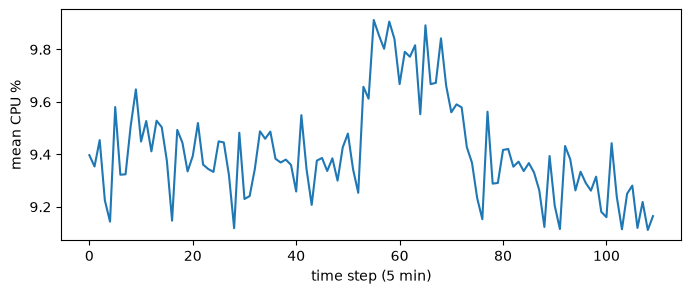

In [4]:
train_ts = ts[:110]
readings = readings[readings["timestamp"].isin(train_ts)]   # from here: training window only

series = build_targets("../challenge_data/vm_cpu_readings.csv.gz").iloc[:110]
print(series["active_vm_count"].nunique(), "different value(s) of active_vm_count")
print(series["aggregate_cpu_utilization"].describe())

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(series.index, series["aggregate_cpu_utilization"])
ax.set_xlabel("time step (5 min)"); ax.set_ylabel("mean CPU %")
plt.show()
fig.savefig("../reports/fig_cpu.png", dpi=150, bbox_inches="tight")

In [5]:
ax.set_title("Fleet-average CPU, training window (110 steps)")

Text(0.5, 1.0, 'Fleet-average CPU, training window (110 steps)')

count    1.100000e+06
mean     9.414089e+00
std      1.427521e+01
min      7.158922e-03
50%      5.119809e+00
90%      1.969112e+01
95%      3.729325e+01
99%      8.740635e+01
max      9.948803e+01
Name: avg_cpu, dtype: float64


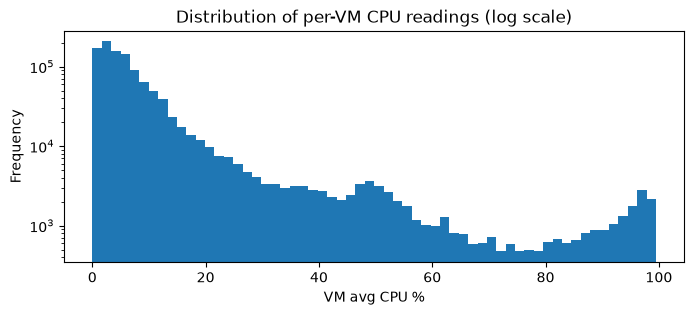

In [6]:
print(readings["avg_cpu"].describe(percentiles=[.5, .9, .95, .99]))
fig, ax = plt.subplots(figsize=(8, 3))
readings["avg_cpu"].plot.hist(bins=60, log=True, ax=ax)
ax.set_xlabel("VM avg CPU %"); ax.set_title("Distribution of per-VM CPU readings (log scale)")
plt.show()
fig.savefig("../reports/fig_hist.png", dpi=150, bbox_inches="tight")

vm_category  Delay-insensitive  Interactive    Unknown
mean                  8.257266    11.505150  10.354689
std                   0.216981     0.243349   0.629017
min                   7.900122    10.950990   9.165476
max                   8.877598    12.016724  11.560735


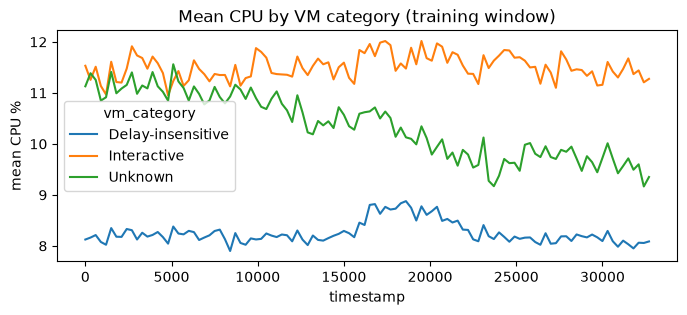

                      count       mean        std
virtual_core_bucket                              
2                    828740   9.764163  14.575251
24                     6820  11.428831  16.344784
4                    209880   7.918723  13.321742
8                     53460   9.658399  12.492935
>24                    1100   6.619469   8.607183


In [7]:
merged = readings.merge(meta[["vm_id", "vm_category", "virtual_core_bucket"]], on="vm_id")
by_cat = merged.groupby(["timestamp", "vm_category"])["avg_cpu"].mean().unstack()
print(by_cat.describe().loc[["mean", "std", "min", "max"]])

fig, ax = plt.subplots(figsize=(8, 3))
by_cat.plot(ax=ax)
ax.set_ylabel("mean CPU %"); ax.set_title("Mean CPU by VM category (training window)")
plt.show()
fig.savefig("../reports/fig_segments.png", dpi=150, bbox_inches="tight")

print(merged.groupby("virtual_core_bucket")["avg_cpu"].agg(["count", "mean", "std"]))

In [8]:
ax.set_xlabel("timestamp (seconds)")

Text(0.5, 36.00488281250001, 'timestamp (seconds)')

In [9]:
cpu = series["aggregate_cpu_utilization"]
print("highest 5 steps:\n", cpu.nlargest(5))
print("lowest 5 steps:\n", cpu.nsmallest(5))
print("lag-1 autocorrelation:", round(cpu.autocorr(lag=1), 3))

highest 5 steps:
 55    9.912175
58    9.906192
65    9.891946
56    9.853998
68    9.842210
Name: aggregate_cpu_utilization, dtype: float64
lowest 5 steps:
 108    9.111634
103    9.114320
91     9.115401
28     9.118488
106    9.119565
Name: aggregate_cpu_utilization, dtype: float64
lag-1 autocorrelation: 0.667


[0.102 0.182 0.109 0.155 0.13  0.064 0.166 0.167 0.221 0.246 0.163 0.173
 0.203 0.208 0.13  0.131 0.121 0.122 0.171 0.203 0.297 0.377 0.159 0.279]


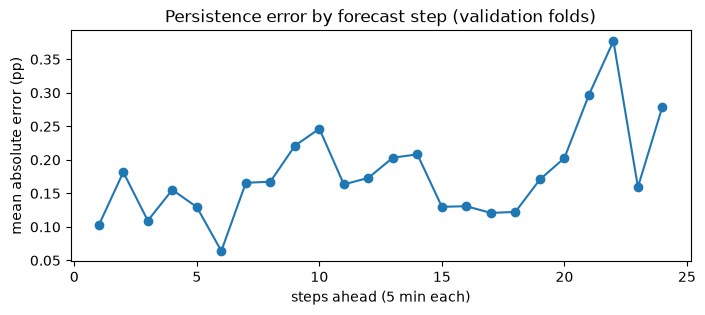

In [10]:
from cwfc.models import CANDIDATES

y = build_targets("../challenge_data/vm_cpu_readings.csv.gz").iloc[:-24]["aggregate_cpu_utilization"].to_numpy()
errs, origin = [], 55
while origin + 24 <= len(y):
    errs.append(np.abs(y[origin:origin + 24] - CANDIDATES["persistence"](y[:origin], 24)))
    origin += 12
mean_err = np.mean(errs, axis=0)
print(mean_err.round(3))

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(range(1, 25), mean_err, marker="o")
ax.set_xlabel("steps ahead (5 min each)"); ax.set_ylabel("mean absolute error (pp)")
ax.set_title("Persistence error by forecast step (validation folds)")
plt.show()
fig.savefig("../reports/fig_error_by_step.png", dpi=150, bbox_inches="tight")

In [15]:
from cwfc.evaluate import collect_folds
from cwfc.models import persistence

a, p, _ = collect_folds(y, persistence, 24, 55, 12)
rmse_val = np.sqrt(np.mean((a - p) ** 2))
print("validation RMSE:", round(rmse_val, 4))
for k in (0.5, 1, 1.28, 1.64, 2):
    print(k, "coverage:", np.mean(a <= p + k * rmse_val).round(3))

validation RMSE: 0.226
0.5 coverage: 0.792
1 coverage: 0.917
1.28 coverage: 0.972
1.64 coverage: 1.0
2 coverage: 1.0
